**For generating plots using Wandb csv.file**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np

try:
    import ipywidgets as widgets
    print("'ipywidgets' is already installed")
except ImportError:
    print("'ipywidgets' not found. Installing now...")
    import sys
    import subprocess
    # 현재 실행 중인 커널의 환경에 정확히 설치하기 위해 sys.executable을 사용합니다.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ipywidgets"])
    import ipywidgets as widgets
    print("'ipywidgets' is installed successfully.")
    
from IPython.display import display, clear_output

'ipywidgets' is already installed


In [2]:
def plot(plot_config, window_size=50, figsize=(8,6), ylim=(0,1)):
    """
    plot_config: list of dicts, each with:
      - path       : str, CSV file path
      - label      : str, legend label
      - keyword    : str, column keyword to match (e.g. 'success_rate', 'PCI_rippo')
      - color      : str, matplotlib color
      - linestyle  : str, optional (default '-')
      - linewidth  : float, optional (default 2)
      - alpha      : float, optional fill_between alpha (default 0.15)
      - exclude    : str, optional keyword to exclude from column matching
    """
    plt.close('all')
    plt.rc('font', size=14)
    plt.rc('axes', labelsize=14)
    plt.rc('xtick', labelsize=14)
    plt.rc('ytick', labelsize=14)
    plt.rc('legend', fontsize=14)

    fig, ax = plt.subplots(figsize=figsize)

    for entry in plot_config:
        file_path = entry['path']
        label     = entry['label']
        keyword   = entry.get('keyword', 'success_rate')
        color     = entry['color']
        lsty      = entry.get('linestyle', '-')
        lw        = entry.get('linewidth', 2)
        alpha     = entry.get('alpha', 0.15)
        exclude   = entry.get('exclude', None)

        try:
            df = pd.read_csv(file_path)
        except FileNotFoundError:
            print(f'[WARN] File not found: {file_path}')
            continue

        # column matching
        clean_kw = keyword.lower().replace('_', '').replace('-', '')
        cols = []
        for col in df.columns:
            col_lower = col.lower()
            if 'success_rate' not in col_lower: continue
            clean_col = col_lower.replace('_', '').replace('-', '')
            if clean_kw not in clean_col: continue
            if 'MIN' in col or 'MAX' in col or '_step' in col: continue
            if exclude and exclude.lower() in col_lower: continue
            cols.append(col)

        if not cols:
            print(f'[WARN] No matching columns for keyword "{keyword}" in {file_path}')
            continue

        x = df['total_steps']
        y_mean = df[cols].mean(axis=1).rolling(window=window_size, min_periods=1).mean()
        y_std  = df[cols].std(axis=1).rolling(window=window_size, min_periods=1).mean()

        ax.plot(x, y_mean, label=label, color=color, linestyle=lsty, linewidth=lw)
        ax.fill_between(x, y_mean - y_std, y_mean + y_std, color=color, alpha=alpha)

    ax.set_xlabel('Total Steps')
    ax.set_ylabel('Success Rate')
    ax.set_ylim(ylim)
    ax.set_xlim((0,3e6))
    ax.legend(loc='upper left')#loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False)
    ax.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    plt.close(fig)


def plot_causal_effect(plot_config, window_size=50, figsize=(10,6)):
    """
    plot_config: list of dicts, each representing ONE causal-effect CSV, with:
      - path       : str, CSV file path (delta_stag / delta_hare / delta_no type)
      - label      : str, legend label prefix
      - color      : str, matplotlib color
      - linestyle  : str, optional (default '-')
      - linewidth  : float, optional (default 2)
      - keyword    : str, column keyword to match (e.g. 'PCI_rippo')
      - case       : str, one of 'stag' | 'hare' | 'no_reward'
                     determines which column pattern to search for
    """
    plt.close('all')
    plt.rc('font', size=14)
    plt.rc('axes', labelsize=14)
    plt.rc('xtick', labelsize=14)
    plt.rc('ytick', labelsize=14)
    plt.rc('legend', fontsize=14)

    case_patterns = {
        'stag':      ('delta_stag_reward',),
        'hare':      ('delta_forage',),
        'no_reward': ('delta_no_reward',),
    }
    case_linestyles = {
        'stag':      '-',
        'hare':      '-',
        'no_reward': '-',
    }

    fig, ax = plt.subplots(figsize=figsize)
    ax.axhline(y=5, color='gray', linestyle=':', alpha=0.5)
    ax.axhline(y=3, color='gray', linestyle=':', alpha=0.5)

    for entry in plot_config:
        file_path = entry['path']
        label     = entry['label']
        color     = entry['color']
        lw        = entry.get('linewidth', 2)
        keyword   = entry['keyword']
        case      = entry.get('case', 'stag').lower()
        alpha     = entry.get('alpha', 0.15)
        
        patterns = case_patterns.get(case, ('delta_stag_reward',))
        final_lsty = entry.get('linestyle', case_linestyles.get(case, '-'))

        try:
            df = pd.read_csv(file_path)
        except FileNotFoundError:
            print(f'[WARN] File not found: {file_path}')
            continue

        clean_kw = keyword.lower().replace('_', '').replace('-', '')
        cols = []
        for col in df.columns:
            col_lower = col.lower()
            clean_col = col_lower.replace('_', '').replace('-', '')
            if clean_kw not in clean_col: continue
            if not any(p in col_lower for p in patterns): continue
            if 'MIN' in col or 'MAX' in col: continue
            cols.append(col)

        if not cols:
            print(f'[WARN] No matching columns for keyword "{keyword}" / case "{case}" in {file_path}')
            continue

        x = df['total_steps']
        y_mean = df[cols].mean(axis=1).rolling(window=window_size, min_periods=1).mean()
        y_std  = df[cols].std(axis=1).rolling(window=window_size, min_periods=1).mean()

        ax.plot(x, y_mean, label=label, color=color, linestyle=final_lsty, linewidth=lw)
        ax.fill_between(x, y_mean - y_std, y_mean + y_std, color=color, alpha=alpha)

    ax.set_xlabel('Total Steps')
    ax.set_xlim((0,3e6))
    ax.set_ylabel('Causal Shaped Reward')
    ax.legend(loc='upper left')#, bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
    ax.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    plt.close(fig)


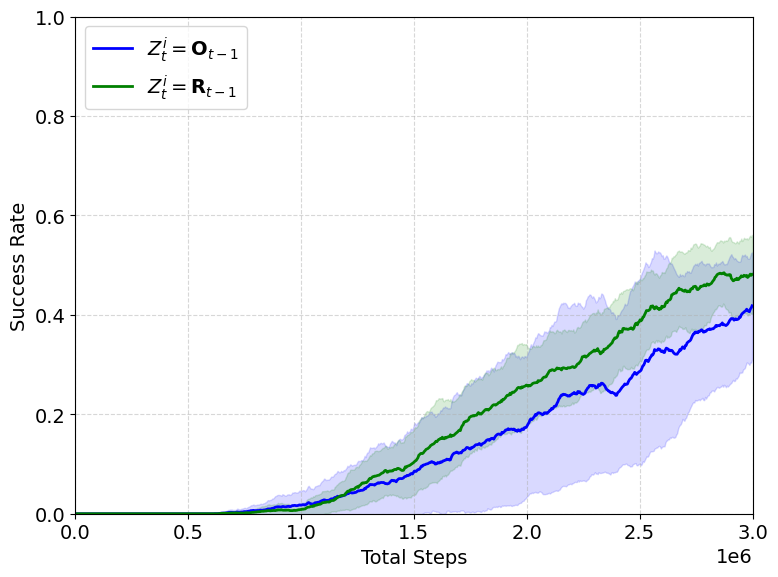

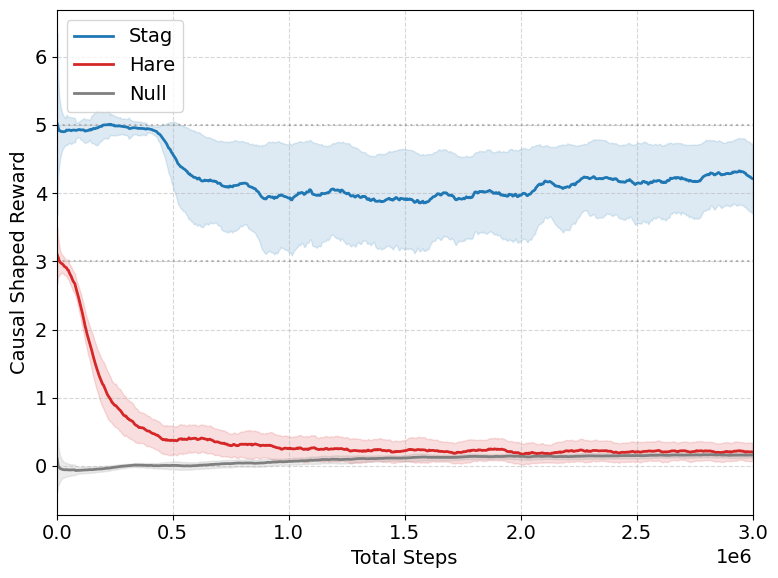

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import os

# ── Success Rate Plot ──────────────────────────────────────────────
# 각 항목에 csv 경로와 시각화 스펙을 직접 설정하세요.
# keyword: csv 내의 컬럼 이름에서 해당 모델을 식별하는 키워드
# exclude: keyword와 함께 쓸 때 제외할 키워드 (optional)
BASE = 'wandb_csv/SH_noisy'

plot_config = [
    {
        'path':      f'{BASE}/sh3_pci_rmappo.csv',
        'label':     '$Z^i_t=\mathbf{O}_{t-1}$',
        'keyword':   'PCI_rmappo',
        'color':     'blue',
        'linestyle': '-',
    },
    # {
    #     'path':      f'{BASE}/sh3_pci_rmappo_z=r.csv',
    #     'label':     'PCI+MAPPO',
    #     'keyword':   'PCI_rmappo',
    #     'color':     'red',
    #     'linestyle': '-',
    # },
    {
        'path':      f'{BASE}/sh3_pci_rmappo_z=r.csv',
        'label':     '$Z^i_t=\mathbf{R}_{t-1}$',
        'keyword':   'rmappo',
        'color':     'green',
        'linestyle': '-',
        #'exclude':   'pci',
    },
    # {
    #     'path':      f'{BASE}/sh3_pci_rmappo.csv',
    #     'label':     'MAPPO',
    #     'keyword':   'rmappo',
    #     'color':     'orange',
    #     'linestyle': '-',
    #     #'exclude':   'pci',
    # },
]

plot(plot_config, figsize=(8,6), window_size=20)

# ── Causal Effect Plot ─────────────────────────────────────────────
# case: 'stag' | 'hare' | 'no_reward'
BASE = 'wandb_csv/SH'
causal_config = [
    {
        'path':    f'{BASE}/sh3_delta_stag.csv',
        'label':   'Stag',
        'keyword': 'PCI_rippo',
        'color':   'tab:blue',
        'case':    'stag',
    },
    {
        'path':    f'{BASE}/sh3_delta_hare.csv',
        'label':   'Hare',
        'keyword': 'PCI_rippo',
        'color':   'tab:red',
        'case':    'hare',
    },
    {
        'path':    f'{BASE}/sh3_delta_no.csv',
        'label':   'Null',
        'keyword': 'PCI_rippo',
        'color':   'tab:gray',
        'case':    'no_reward',
    },
]

plot_causal_effect(causal_config, figsize=(8,6), window_size=20)
